# Analyse du domain shift (lorsque le modèle est face à un centre qu'il n'a jamais vu)

Les 5 hôpitaux de CAMELYON17 n'ont ni les mêmes scanners ni exactement la même coloration H&E, ce qui peut entraîner du
domain shift. Notre modèle peut apprendre sur des centres mais donc moins bien marcher sur un nouveau centre médical.
Dans notre sélection, les 5 centres sont présents à l'entraînement donc les résultats par centre (notebook
`02_modelisation_evaluation`, parties 4 et 7) ne disent pas ce qui se passerait sur un hôpital jamais vu.

Les différences de couleur entre centres et l'effet de la normalisation des couleurs (Reinhard, Macenko) sont étudiés
dans l'analyse `analyses/multicentres` : sur les patchs du prototype, la normalisation n'apporte pas de gain
en validation.

Ici, nous faisons une analyse complémentaire sur notre modèle final à partir des patchs d'entraînement et de validation en mettant un centre de côté. Pour chaque centre, on mesure l'AUC sur ses patchs de validation avec deux modèles, l'un entraîné sur les 5 centres (centre vu), l'autre sur les 4 autres centres seulement (centre jamais vu).

Le test et les réglages figés ne sont pas touchés pour que seule la présence du centre à l'entraînement change.


## 1. Prérequis et données

Ce notebook ne recalcule rien de long : il relit les patchs de la variante retenue et leurs caractéristiques ResNet18 déjà calculées. Il faut donc avoir lancé avant (ces fichiers ne sont pas dans Git) :
- le découpage de la variante retenue : `python extract_patches.py --variante retenue` (dossier `patches/retenue/niveau_2`)
- la partie 2 du notebook `02_modelisation_evaluation` (fichier `resultats/caracteristiques/retenue_niveau_2.npz`) et sa partie 6.4 (fichier `resultats/reglages_figes.json` pour la valeur de C).

In [1]:
import os
import json
from pathlib import Path

# On se place dans version_finale/ (comme les autres notebooks), pour avoir les mêmes chemins que les scripts
dossier = Path.cwd()
while not (dossier / "extract_patches.py").exists() and dossier != dossier.parent:
    dossier = dossier.parent
os.chdir(dossier)
print("Dossier de travail :", Path.cwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

VARIANTE, NIVEAU = "retenue", 2
reglages = json.loads(Path("resultats/reglages_figes.json").read_text())
C_RETENU = reglages["C"]

tableau = pd.read_csv(Path("patches") / VARIANTE / f"niveau_{NIVEAU}" / "patches.csv")
X = np.load(Path("resultats/caracteristiques") / f"{VARIANTE}_niveau_{NIVEAU}.npz")["X"]
assert len(X) == len(tableau), "Caractéristiques et patchs ne correspondent pas : relancer la partie 2 du notebook 02"
y = (tableau["label"] == "tumor").astype(int).to_numpy()
print("Réglages figés :", reglages)
print(tableau.groupby(["set", "center", "label"]).size().unstack(fill_value=0))


Dossier de travail : c:\Users\joell\projets\projet-camelyon17\version_finale
Réglages figés : {'variante': 'retenue', 'niveau': 2, 'seuil_lame': 0.9, 'taille_min_lesion_um': 600.0, 'C': 0.001, 'date': '2026-11-20 14:50'}
label                normal  tumor
set          center               
entrainement 0.0       1739    386
             1.0       1747    526
             2.0       1730    592
             3.0       1740    263
             4.0       1642    284
validation   0.0        498    109
             1.0        497     13
             2.0        490    250
             3.0        498     17
             4.0        445    249


## 2. Un centre de côté

Pour chaque centre, les mêmes patchs sont évalués, seul l'entraînement change :
- centre vu : régression logistique entraînée sur les patchs d'entraînement des 5 centres (comme le modèle final)
- centre jamais vu : entraînée sur les patchs d'entraînement des 4 autres centres

L'écart entre les deux AUC mesure la perte de performance sur un centre quand le modèle ne l'a jamais vu.

In [2]:
entr = (tableau["set"] == "entrainement").to_numpy()
val = (tableau["set"] == "validation").to_numpy()
centres = tableau["center"].to_numpy()

def nouveau_modele():
    """Même modèle que le modèle final : standardisation + régression logistique, C fixé, classes équilibrées."""
    return make_pipeline(StandardScaler(), LogisticRegression(C=C_RETENU, class_weight="balanced", max_iter=5000))

avec_tous = nouveau_modele().fit(X[entr], y[entr])
lignes = []
for c in sorted(np.unique(centres)):
    evalue = val & (centres == c)
    sans_c = nouveau_modele().fit(X[entr & (centres != c)], y[entr & (centres != c)])
    auc_vu = roc_auc_score(y[evalue], avec_tous.predict_proba(X[evalue])[:, 1])
    auc_jamais_vu = roc_auc_score(y[evalue], sans_c.predict_proba(X[evalue])[:, 1])
    lignes.append({"centre": int(c), "patchs évalués": int(evalue.sum()), "dont tumoraux": int(y[evalue].sum()),
                   "AUC centre vu": round(auc_vu, 3), "AUC centre jamais vu": round(auc_jamais_vu, 3),
                   "écart": round(auc_jamais_vu - auc_vu, 3)})
domain_shift = pd.DataFrame(lignes)
domain_shift.to_csv(Path("resultats") / "domain_shift_un_centre_de_cote.csv", index=False)
print("Écart moyen :", round(domain_shift["écart"].mean(), 3))
domain_shift.style.hide(axis="index")


Écart moyen : 0.005


centre,patchs évalués,dont tumoraux,AUC centre vu,AUC centre jamais vu,écart
0,607,109,0.906000,0.879000,-0.027000
1,510,13,0.804000,0.841000,0.037000
2,740,250,0.970000,0.972000,0.002000
3,515,17,0.868000,0.873000,0.005000
4,694,249,0.960000,0.967000,0.007000


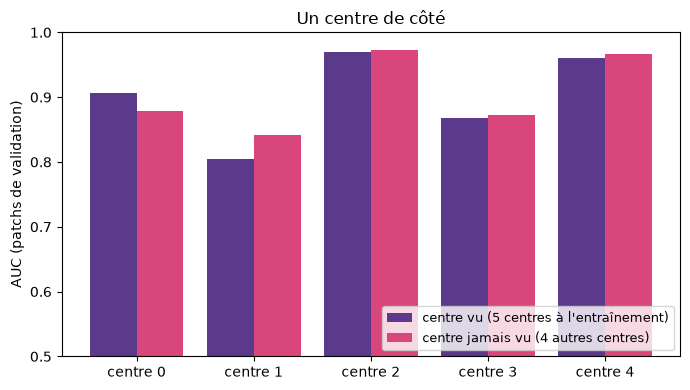

In [3]:
# Figure : AUC par centre, centre vu ou jamais vu
x = np.arange(len(domain_shift))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - 0.2, domain_shift["AUC centre vu"], width=0.4, label="centre vu (5 centres à l'entraînement)", color="#5B3A8C")
ax.bar(x + 0.2, domain_shift["AUC centre jamais vu"], width=0.4, label="centre jamais vu (4 autres centres)", color="#D9467C")
ax.set_xticks(x, [f"centre {c}" for c in domain_shift["centre"]])
ax.set_ylim(0.5, 1); ax.set_ylabel("AUC (patchs de validation)")
ax.legend(loc="lower right", fontsize=9); ax.set_title("Un centre de côté")
plt.tight_layout()


## 3. Résultats et analyse du domain shift



**Ce que montre l'analyse avec un centre de côté**

- L'AUC ne baisse presque pas quand le centre n'a jamais été vu :
  - Seul le centre 0 perd un peu (0,906 à 0,879, soit −0,027)
  - Les centres 2, 3 et 4 ne bougent presque pas (+0,002 à +0,007)
  - Le centre 1 gagne même un peu (0,804 à 0,841) mais il n'a que 13 patchs tumoraux en validation. De même, le centre 3
    n'en a que 17 donc sur si peu d'exemples, quelques patchs suffisent à faire varier l'AUC. Il faut noter que ces deux valeurs sont fragiles.
- Avec notre modèle (ResNet18 ImageNet gelé et régression logistique simple), nous arrivons bien à transférer la capacité à classer
  un patch tumoral au-dessus d'un patch sain d'un centre à l'autre. Le modèle ne semble donc pas apprendre de détail propre à un centre qui serait indispensable pour reconnaître la tumeur.
- Le centre 1 apparait difficile, qu'il soit vu ou non par le modèle en entraînement (AUC autour de 0,80 à 0,84). Cela ne vient pas d'un manque
  d'exemples à l'entraînement donc à priori plutôt de ses lames elles-mêmes (lames plus "difficiles", coloration, etc.).


**Ce que montrent d'autres résultats de notre travail**

- Les résultats par centre sur les patchs (notebook 02, partie 4) montrent des résultats différents suivant les centres : AUC de 0,80 (centre 1) à 0,97 (centre 2). Le modèle performe donc mieux sur certains centres que d'autres.


**Les mesures mises en place pour traiter le doman shift et assurer la transférabilité de la capacité du modèle sur de nouveaux centres**

1. Concernant la taille des pixels : elle peut être différente selon le scanner et donc le centre, comme vu dans le notebook 01. Nous avons donc choisi de découper les patchs sur la base d'une surface fixe de 112 µm.
2. Concernant l'aspect des lames : certains scanners laissent des zones vides noires et nous les avons donc mises en blanc. Par ailleurs, certaines lames avaient du tissu pâle qui se perdait avec un seuil de saturation trop élevé utilisé pour la détection du tissu : nous l'avons sélectionné en fonction.
3. Concernant la normalisation des couleurs, nous avons pu voir que Reinhard et Macenko n'amélioraient pas l'AUC sur nos sets et faisaient baisser la spécificité. Nous avons donc choisi de garder les images d'origine. A noter que, comme pour, globalement, tous nos résultats, une limite est celle du volume relativement faible de nos sets.


**Les limites de nos analyses**

- Notre analyse ne regarde que la performance du modèle de patch mais ne regarde pas le reste de la chaine. Or, deux réglages sont utilisés pour classer la lame (le seuil et la taille minimale). Nous les avons choisis en regardant les lames de validation des 5 centres et ils ont donc vu tous les centres. On ne sait pas si un seuil choisi sans un centre marcherait aussi bien sur ce centre. 
- La validation ne compte que 2 lames par centre donc nous avons peu de cas pour le calcul de l'AUC.
- Les 4 centres restants couvrent déjà une grande variété de colorations. Un centre vraiment différent présenterait peut-être un AUC plus faible.
- Les écarts entre centres mélangent l'effet du centre et celui des lésions (leur taille ou type) donc on ne peut pas attribuer une différence au seul centre.


**Les pistes identifiées**

1. Pendant l’entraînement d'un modèle ResNet18 non figé, on pourrait faire de l'augmentation de couleur : modifier un peu les couleurs des patchs au hasard pour que le modèle apprenne ainsi à reconnaître la tumeur dans des colorations différentes. Mais il faut donc réentraîner ResNet18, ce que nous ne faisions pas dans notre approche.
2. Refaire l'analyse au niveau des lames : choisir le seuil et la taille minimale sans un centre puis classer ses lames de validation.
4. Utiliser plus de lames par centre pour avoir des comparaisons entre centres plus fiables.